In [11]:
# 0. 필요한 라이브러리
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
import csv
import time

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("성능 평가 라이브러리 준비 완료!")

성능 평가 라이브러리 준비 완료!


In [12]:
from pathlib import Path

print("현재 작업 폴더:", Path.cwd())

csv_path = Path.cwd() / "pikipick_baseline_results.csv"

print("CSV 파일 존재 여부:", csv_path.exists())

현재 작업 폴더: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training
CSV 파일 존재 여부: True


In [13]:
# ============================================================
# 1. MediaPipe Gesture Recognizer 모델 파일 확인
# 목적: 성능 평가에 사용할 모델이 정상적으로 저장되어 있는지 확인
# ============================================================

# 1) 파일 및 폴더 경로를 관리하는 라이브러리
from pathlib import Path

# 2) 현재 Jupyter Notebook이 실행되는 폴더 확인
current_path = Path.cwd()

print("현재 작업 폴더:", current_path)

# 3) MediaPipe 모델 파일 경로 설정
# mediapipe_training 폴더의 상위 폴더로 이동한 뒤
# mediapipe_hand 폴더에서 모델 파일을 찾음
MODEL_PATH = (
    current_path.parent
    / "mediapipe_hand"
    / "gesture_recognizer.task"
)

# 4) 모델 파일이 실제로 존재하는지 확인
print("모델 파일 경로:", MODEL_PATH)
print("모델 파일 존재 여부:", MODEL_PATH.is_file())

# 5) 모델 파일이 없는 경우 오류 발생
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"MediaPipe 모델 파일을 찾을 수 없습니다: {MODEL_PATH}"
    )

# 6) 정상 확인 메시지
print("MediaPipe 모델 파일 확인 완료!")

현재 작업 폴더: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training
모델 파일 경로: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_hand\gesture_recognizer.task
모델 파일 존재 여부: True
MediaPipe 모델 파일 확인 완료!


In [14]:

# ============================================================
# 2. MediaPipe 가위바위보 성능 평가 데이터 수집
# 목적: 실제 손동작과 모델 예측 결과를 비교할 데이터 생성
# ============================================================

# 0. 필요한 라이브러리
import cv2
import mediapipe as mp
import time
import csv

from pathlib import Path


# 1. 모델 파일 경로
# 앞 단계에서 확인한 모델 파일 사용
MODEL_PATH = (
    Path.cwd().parent
    / "mediapipe_hand"
    / "gesture_recognizer.task"
)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"모델 파일 없음: {MODEL_PATH}")


# 2. MediaPipe Gesture Recognizer 설정
BaseOptions = mp.tasks.BaseOptions
GestureRecognizer = mp.tasks.vision.GestureRecognizer
GestureRecognizerOptions = mp.tasks.vision.GestureRecognizerOptions
RunningMode = mp.tasks.vision.RunningMode

options = GestureRecognizerOptions(
    base_options=BaseOptions(
        model_asset_buffer=MODEL_PATH.read_bytes()
    ),
    running_mode=RunningMode.VIDEO,
    num_hands=1
)


# 3. MediaPipe 결과를 가위바위보 이름으로 변환
RPS_MAP = {
    "Closed_Fist": "ROCK",
    "Victory": "SCISSORS",
    "Open_Palm": "PAPER"
}


# 4. 키보드 입력을 실제 정답으로 지정
# 카메라 화면을 클릭한 후 숫자 키를 누르면 기록됨
KEY_MAP = {
    ord("1"): "ROCK",
    ord("2"): "SCISSORS",
    ord("3"): "PAPER"
}


# 5. 평가 데이터 저장 리스트
records = []

# 5. 기존 CSV 데이터 불러오기
import csv
from pathlib import Path

# 기존 평가 CSV 파일 경로
output_path = Path.cwd() / "pikipick_baseline_results.csv"

# 기존 데이터 저장 리스트
records = []

# 기존 CSV 파일이 있으면 데이터 불러오기
if output_path.is_file():
    with output_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as f:
        records = list(csv.DictReader(f))

print("기존 데이터 수:", len(records))


# 6. 웹캠 실행
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    raise RuntimeError("웹캠 연결 실패!")

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

print("PIKIPICK 성능 평가 데이터 수집 시작!")
print("1 = 바위 / 2 = 가위 / 3 = 보")
print("Q = 평가 종료 및 CSV 저장")


# 7. 실시간 모델 예측 및 평가 데이터 수집
try:
    with GestureRecognizer.create_from_options(
        options
    ) as recognizer:

        start_time = time.monotonic()
        last_timestamp = -1

        while True:

            # 8. 웹캠 프레임 읽기
            success, frame = cap.read()

            if not success:
                print("카메라 영상 읽기 실패")
                break

            # 화면 좌우 반전
            frame = cv2.flip(frame, 1)

            # 9. OpenCV BGR 영상을 RGB로 변환
            rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            # 10. VIDEO 모드 타임스탬프
            timestamp = int(
                (time.monotonic() - start_time) * 1000
            )

            timestamp = max(
                timestamp,
                last_timestamp + 1
            )

            last_timestamp = timestamp

            # 11. MediaPipe 손동작 예측
            result = recognizer.recognize_for_video(
                mp_image,
                timestamp
            )

            # 손 관절 검출 여부
            hand_detected = bool(result.hand_landmarks)

            # 기본 예측값
            model_name = "None"
            confidence = 0.0
            prediction = "UNKNOWN"

            # 12. 모델 예측 결과 추출
            if result.gestures and result.gestures[0]:

                category = result.gestures[0][0]

                model_name = category.category_name
                confidence = category.score

                prediction = RPS_MAP.get(
                    model_name,
                    "UNKNOWN"
                )

            # 13. 카메라 화면에 예측 결과 표시
            cv2.putText(
                frame,
                f"Prediction: {prediction}",
                (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 255),
                2
            )

            cv2.putText(
                frame,
                f"Model: {model_name} ({confidence:.2f})",
                (15, 70),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                2
            )

            cv2.putText(
                frame,
                f"Saved Samples: {len(records)}",
                (15, 105),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                2
            )

            cv2.imshow(
                "PIKIPICK - Data Collection",
                frame
            )

            # 14. 키보드 입력 확인
            key = cv2.waitKey(1) & 0xFF

            # 숫자 키를 누르면 현재 프레임 기록
            if key in KEY_MAP:

                true_label = KEY_MAP[key]

                records.append({
                    "true_label": true_label,
                    "prediction": prediction,
                    "model_name": model_name,
                    "confidence": confidence,
                    "hand_detected": int(hand_detected),
                    "timestamp_ms": timestamp
                })

                print(
                    f"[{len(records)}] "
                    f"정답: {true_label} | "
                    f"예측: {prediction} | "
                    f"손 검출: {hand_detected}"
                )

            # Q 키로 종료
            elif key == ord("q"):
                break

finally:
    # 15. 웹캠과 화면 종료
    cap.release()
    cv2.destroyAllWindows()


# 16. 수집한 데이터를 CSV 파일로 저장
output_path = (
    Path.cwd() / "pikipick_baseline_results.csv"
)

with output_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "true_label",
            "prediction",
            "model_name",
            "confidence",
            "hand_detected",
            "timestamp_ms"
        ]
    )

    writer.writeheader()
    writer.writerows(records)


# 17. 수집 결과 출력
print("=" * 45)
print("PIKIPICK 데이터 수집 완료!")
print("총 데이터 수:", len(records))
print("CSV 저장 위치:", output_path)
print("=" * 45)


기존 데이터 수: 156
PIKIPICK 성능 평가 데이터 수집 시작!
1 = 바위 / 2 = 가위 / 3 = 보
Q = 평가 종료 및 CSV 저장
[157] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[158] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[159] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[160] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[161] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[162] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[163] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[164] 정답: SCISSORS | 예측: SCISSORS | 손 검출: True
[165] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[166] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[167] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
PIKIPICK 데이터 수집 완료!
총 데이터 수: 167
CSV 저장 위치: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training\pikipick_baseline_results.csv


In [15]:
# 18. 성능 평가 CSV 생성 확인
from pathlib import Path

csv_path = Path.cwd() / "pikipick_baseline_results.csv"

print("CSV 존재 여부:", csv_path.exists())
print("CSV 저장 경로:", csv_path)

CSV 존재 여부: True
CSV 저장 경로: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training\pikipick_baseline_results.csv


PIKIPICK - MediaPipe 기본 모델 성능
평가 샘플 수 : 167
손 검출률    : 100.00%
Accuracy     : 23.35%

[Classification Report]
              precision    recall  f1-score   support

        ROCK     1.0000    0.1905    0.3200        21
    SCISSORS     1.0000    0.1250    0.2222       104
       PAPER     1.0000    0.5238    0.6875        42

   micro avg     1.0000    0.2335    0.3786       167
   macro avg     1.0000    0.2798    0.4099       167
weighted avg     1.0000    0.2335    0.3515       167



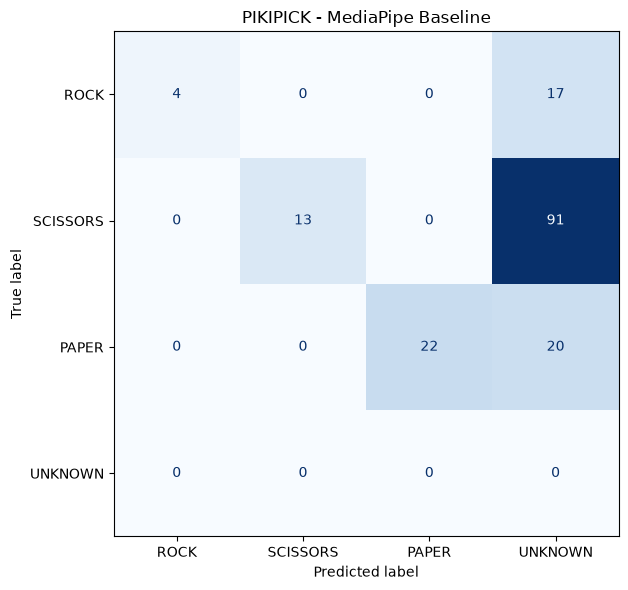


[가위 인식 분석]
가위 평가 수: 104
가위 인식 성공: 13
UNKNOWN 예측: 91
가위 재현율: 12.50%


In [16]:

# 10. 저장된 CSV 불러오기
csv_path = Path.cwd() / "pikipick_baseline_results.csv"

with csv_path.open(
    "r", encoding="utf-8-sig", newline=""
) as f:
    records = list(csv.DictReader(f))

if not records:
    raise ValueError("평가 데이터가 없습니다.")

# 실제 정답과 모델 예측
y_true = [r["true_label"] for r in records]
y_pred = [r["prediction"] for r in records]

labels = ["ROCK", "SCISSORS", "PAPER"]
matrix_labels = labels + ["UNKNOWN"]

# 11. 정확도
accuracy = accuracy_score(y_true, y_pred)

# 12. 손 검출률
detected_count = sum(
    int(r["hand_detected"]) for r in records
)
detection_rate = detected_count / len(records)

print("=" * 45)
print("PIKIPICK - MediaPipe 기본 모델 성능")
print("=" * 45)
print(f"평가 샘플 수 : {len(records)}")
print(f"손 검출률    : {detection_rate * 100:.2f}%")
print(f"Accuracy     : {accuracy * 100:.2f}%")

# 13. 클래스별 성능
# UNKNOWN 예측은 틀린 예측으로 반영
print("\n[Classification Report]")

print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0,
        digits=4
    )
)

# 14. 혼동행렬
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=matrix_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=matrix_labels
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("PIKIPICK - MediaPipe Baseline")
plt.tight_layout()
plt.show()

# 15. 가위 인식 결과 별도 분석
scissors_rows = [
    r for r in records
    if r["true_label"] == "SCISSORS"
]

if scissors_rows:
    scissors_correct = sum(
        r["prediction"] == "SCISSORS"
        for r in scissors_rows
    )

    scissors_unknown = sum(
        r["prediction"] == "UNKNOWN"
        for r in scissors_rows
    )

    print("\n[가위 인식 분석]")
    print("가위 평가 수:", len(scissors_rows))
    print("가위 인식 성공:", scissors_correct)
    print("UNKNOWN 예측:", scissors_unknown)
    print(
        "가위 재현율:",
        f"{scissors_correct / len(scissors_rows) * 100:.2f}%"
    )


In [1]:
# ============================================================
# 3. MediaPipe 학습 데이터 확인
# ============================================================

# 0. 필요한 라이브러리
import pandas as pd
from pathlib import Path

# 1. 학습 데이터 CSV 경로
csv_path = Path.cwd() / "landmarks_dataset.csv"

# 2. 데이터 불러오기
df = pd.read_csv(csv_path)

# 3. 수집 결과 출력
print("전체 데이터:", len(df))
print("데이터 크기:", df.shape)

print("\n[클래스별 데이터 개수]")
print(df["label"].value_counts())

print("\n[촬영 세션별 개수]")
print(df["session_id"].value_counts())

# 4. 데이터 일부 확인
display(df.head())

전체 데이터: 104
데이터 크기: (104, 66)

[클래스별 데이터 개수]
label
SCISSORS    36
PAPER       35
ROCK        30
NONE         3
Name: count, dtype: int64

[촬영 세션별 개수]
session_id
20261106_183039    104
Name: count, dtype: int64


,session_id,label,handedness,x0,y0,z0,x1,y1,z1,x2,...,z17,x18,y18,z18,x19,y19,z19,x20,y20,z20
0,20261106_183039,ROCK,Right,-0.026988,0.082852,-0.024991,0.010579,0.065629,-0.031794,0.030013,...,-0.012705,-0.032576,-0.004180,-0.031247,-0.026512,0.012468,-0.039658,-0.033100,0.018150,-0.025703
1,20261106_183039,ROCK,Right,-0.030937,0.088272,-0.017963,0.005831,0.069437,-0.017637,0.030583,...,-0.022366,-0.024000,0.003333,-0.041527,-0.017778,0.018050,-0.048359,-0.030422,0.023693,-0.036058
2,20261106_183039,ROCK,Right,-0.012541,0.045376,0.074168,0.014215,0.030099,0.057507,0.032842,...,-0.001711,-0.008732,0.030510,-0.007748,-0.004195,0.030935,0.015462,-0.012452,0.020969,0.030661
3,20261106_183039,ROCK,Right,-0.020057,0.037821,0.087730,0.007125,0.017744,0.061185,0.024176,...,0.000596,-0.006935,0.030059,-0.000446,-0.002077,0.033059,0.021954,-0.011381,0.026097,0.039347
4,20261106_183039,ROCK,Right,0.017376,0.000151,0.088990,-0.003976,-0.013999,0.063372,-0.019039,...,0.009204,0.028676,-0.015426,0.006324,0.027267,-0.017372,0.027597,0.027732,-0.007538,0.048111


In [2]:
# ============================================================
# 4. MediaPipe 학습 데이터 품질 확인
# 목적: 클래스별 수집량과 결측값 확인
# ============================================================

# 0. 필요한 라이브러리
import pandas as pd
from pathlib import Path

# 1. CSV 파일 불러오기
csv_path = Path.cwd() / "landmarks_dataset.csv"
df = pd.read_csv(csv_path)

# 2. 전체 데이터 크기 확인
print("전체 데이터 수:", len(df))
print("전체 열 개수:", len(df.columns))

# 3. 클래스별 데이터 수 확인
print("\n[가위바위보 클래스별 개수]")
print(df["label"].value_counts())

# 4. 손 종류 확인
print("\n[왼손 / 오른손]")
print(df["handedness"].value_counts())

# 5. 촬영 세션 확인
print("\n[촬영 세션별 개수]")
print(df["session_id"].value_counts())

# 6. 결측값 확인
print("\n[결측값 총 개수]")
print(df.isnull().sum().sum())

# 7. 중복 데이터 확인
print("\n[완전히 동일한 행 개수]")
print(df.duplicated().sum())


전체 데이터 수: 104
전체 열 개수: 66

[가위바위보 클래스별 개수]
label
SCISSORS    36
PAPER       35
ROCK        30
NONE         3
Name: count, dtype: int64

[왼손 / 오른손]
handedness
Right    102
Left       2
Name: count, dtype: int64

[촬영 세션별 개수]
session_id
20261106_183039    104
Name: count, dtype: int64

[결측값 총 개수]
0

[완전히 동일한 행 개수]
0


In [4]:
# ============================================================
# 5. MediaPipe 추가 학습 데이터 수집
# 목적: 기존 CSV에 새로운 손 관절 데이터 추가
# ============================================================

# 0. Python 스크립트 실행
# !를 붙이면 Jupyter에서 터미널 명령어 실행 가능

import sys

!{sys.executable} collect_landmarks.py

PIKIPICK 학습 데이터 수집 시작!
1=바위, 2=가위, 3=보, 4=기타 동작
Q=저장 후 종료
수집 완료!
이번 세션 수집 개수: {'ROCK': 0, 'SCISSORS': 0, 'PAPER': 0, 'NONE': 0}
저장 경로: C:\Users\mbc\rock\mediapipe_training\landmarks_dataset.csv


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793958506.884915   10072 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793958506.895363   15732 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793958507.352017   15732 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


In [5]:
# ============================================================
# 5. MediaPipe 추가 데이터 저장 확인
# ============================================================

# 0. 필요한 라이브러리
import pandas as pd
from pathlib import Path

# 1. CSV 경로 설정
csv_path = Path.cwd() / "landmarks_dataset.csv"

# 2. CSV 데이터 불러오기
df = pd.read_csv(csv_path)

# 3. 저장된 전체 데이터 확인
print("전체 데이터 수:", len(df))

# 4. 클래스별 데이터 확인
print("\n[클래스별 개수]")
print(df["label"].value_counts())

# 5. 촬영 세션 확인
print("\n[촬영 세션]")
print(df["session_id"].value_counts())

# 6. 마지막에 저장된 데이터 확인
print("\n[최근 저장 데이터]")
display(df[["session_id", "label", "handedness"]].tail(10))


전체 데이터 수: 104

[클래스별 개수]
label
SCISSORS    36
PAPER       35
ROCK        30
NONE         3
Name: count, dtype: int64

[촬영 세션]
session_id
20261106_183039    104
Name: count, dtype: int64

[최근 저장 데이터]


,session_id,label,handedness
94,20261106_183039,PAPER,Right
95,20261106_183039,NONE,Right
96,20261106_183039,NONE,Right
97,20261106_183039,NONE,Right
98,20261106_183039,SCISSORS,Right
99,20261106_183039,SCISSORS,Right
100,20261106_183039,SCISSORS,Right
101,20261106_183039,SCISSORS,Right
102,20261106_183039,SCISSORS,Right
103,20261106_183039,SCISSORS,Right


In [6]:
# ============================================================
# 7. 추가 수집한 학습 데이터 최종 확인
# ============================================================

# 0. 필요한 라이브러리
import pandas as pd
from pathlib import Path

# 1. CSV 파일 경로
csv_path = Path.cwd() / "landmarks_dataset.csv"

# 2. CSV 파일을 새로 읽기
df = pd.read_csv(csv_path)

# 3. 전체 데이터 수 확인
print("전체 데이터:", len(df))

# 4. 클래스별 수집 개수
print("\n[가위바위보 데이터]")
print(df["label"].value_counts())

# 5. 추가 촬영 세션 확인
print("\n[촬영 세션별 데이터]")
print(df["session_id"].value_counts())

# 6. 마지막 10개 데이터 확인
print("\n[최근 저장된 데이터]")
display(df[["session_id", "label", "handedness"]].tail(10))

전체 데이터: 104

[가위바위보 데이터]
label
SCISSORS    36
PAPER       35
ROCK        30
NONE         3
Name: count, dtype: int64

[촬영 세션별 데이터]
session_id
20261106_183039    104
Name: count, dtype: int64

[최근 저장된 데이터]


,session_id,label,handedness
94,20261106_183039,PAPER,Right
95,20261106_183039,NONE,Right
96,20261106_183039,NONE,Right
97,20261106_183039,NONE,Right
98,20261106_183039,SCISSORS,Right
99,20261106_183039,SCISSORS,Right
100,20261106_183039,SCISSORS,Right
101,20261106_183039,SCISSORS,Right
102,20261106_183039,SCISSORS,Right
103,20261106_183039,SCISSORS,Right


In [7]:
# ============================================================
# 8. MediaPipe 학습 데이터 CSV 저장 위치 확인
# ============================================================

from pathlib import Path
import pandas as pd

# 1. 현재 Jupyter 작업 위치 확인
print("현재 작업 폴더:", Path.cwd())

# 2. 프로젝트 폴더 아래 CSV 파일 전체 검색
project_dir = Path.cwd()

if project_dir.name == "mediapipe_training":
    project_dir = project_dir.parent

csv_files = list(project_dir.rglob("landmarks_dataset.csv"))

# 3. 발견된 CSV 파일 정보 확인
for path in csv_files:
    df_check = pd.read_csv(path)

    print("\n파일 위치:", path)
    print("전체 데이터:", len(df_check))
    print("촬영 세션:", df_check["session_id"].unique())

현재 작업 폴더: c:\Users\mbc\rock\mediapipe_training

파일 위치: c:\Users\mbc\rock\mediapipe_training\landmarks_dataset.csv
전체 데이터: 104
촬영 세션: <StringArray>
['20261106_183039']
Length: 1, dtype: str


In [8]:
# 추가 수집 결과 최종 확인
import pandas as pd

df = pd.read_csv("landmarks_dataset.csv")

print("전체 데이터:", len(df))
print("\n클래스별 데이터:")
print(df["label"].value_counts())
print("\n촬영 세션:")
print(df["session_id"].value_counts())

전체 데이터: 144

클래스별 데이터:
label
SCISSORS    46
PAPER       45
ROCK        40
NONE        13
Name: count, dtype: int64

촬영 세션:
session_id
20261106_183039    104
20261106_185536     40
Name: count, dtype: int64


[원본 데이터]
전체: 144
label
SCISSORS    46
PAPER       45
ROCK        40
NONE        13
Name: count, dtype: int64

[이번 학습에 사용하는 데이터]
전체: 131
label
SCISSORS    46
PAPER       45
ROCK        40
Name: count, dtype: int64

[데이터 분리]
학습: 101 개
평가: 30 개

모델 학습 완료!

========== 모델 평가 결과 ==========
Accuracy: 60.00%

[클래스별 성능]
              precision    recall  f1-score   support

        ROCK     0.5000    0.1000    0.1667        10
    SCISSORS     0.4375    0.7000    0.5385        10
       PAPER     0.8333    1.0000    0.9091        10

    accuracy                         0.6000        30
   macro avg     0.5903    0.6000    0.5381        30
weighted avg     0.5903    0.6000    0.5381        30



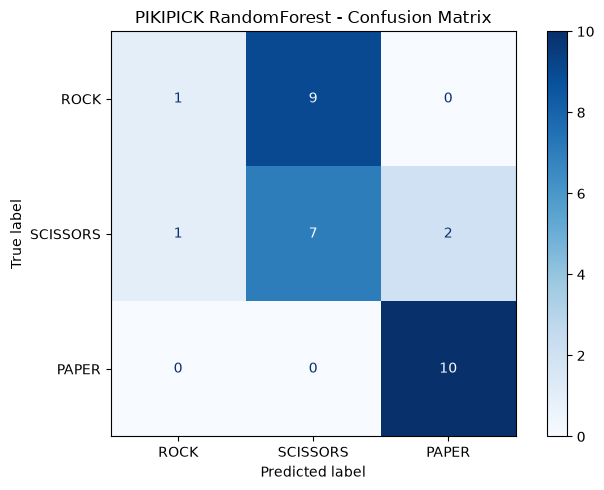


[모델 저장 완료]
c:\Users\mbc\rock\mediapipe_training\pikipick_rps_randomforest.joblib


In [9]:

# ============================================================
# 10. PIKIPICK 전용 가위바위보 AI 모델 학습
# 모델: RandomForestClassifier
# 입력: MediaPipe 손 관절 21개 × 3차원 = 63개
# 출력: ROCK / SCISSORS / PAPER
# 검증: 촬영 세션별 분리
# ============================================================

# 0. 필요한 라이브러리
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. 파일 및 저장 경로 설정
BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "landmarks_dataset.csv"
MODEL_PATH = BASE_DIR / "pikipick_rps_randomforest.joblib"

# 2. 데이터 불러오기
df = pd.read_csv(CSV_PATH)

print("[원본 데이터]")
print("전체:", len(df))
print(df["label"].value_counts())

# 3. 첫 모델은 가위/바위/보만 사용
LABELS = ["ROCK", "SCISSORS", "PAPER"]

data = df[df["label"].isin(LABELS)].copy()

print("\n[이번 학습에 사용하는 데이터]")
print("전체:", len(data))
print(data["label"].value_counts())

# 4. 손 관절 좌표 컬럼 설정
FEATURE_COLUMNS = [
    f"{axis}{i}"
    for i in range(21)
    for axis in ("x", "y", "z")
]

# 5. 관절 좌표 정규화 함수
# 손목(0번)을 원점으로 옮기고
# 손바닥 크기를 기준으로 좌표 크기를 조절
def normalize_landmarks(values):
    points = np.asarray(
        values, dtype=np.float32
    ).reshape(21, 3).copy()

    # 손목 위치를 기준점으로 설정
    points -= points[0]

    # 손목과 중지 시작 관절(9번) 사이 거리
    scale = np.linalg.norm(points[9])

    # 0으로 나누는 것 방지
    if scale < 1e-6:
        scale = 1.0

    points /= scale

    return points.flatten()

# 6. 모든 데이터에 동일한 정규화 적용
X = np.stack([
    normalize_landmarks(row)
    for row in data[FEATURE_COLUMNS].to_numpy()
])

y = data["label"].to_numpy()

# 7. 촬영 세션 기준으로 학습/평가 분리
SESSION_TRAIN = "20261106_183039"
SESSION_TEST = "20261106_185536"

train_mask = (
    data["session_id"].astype(str).to_numpy()
    == SESSION_TRAIN
)

test_mask = (
    data["session_id"].astype(str).to_numpy()
    == SESSION_TEST
)

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("\n[데이터 분리]")
print("학습:", len(X_train), "개")
print("평가:", len(X_test), "개")

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError(
        "학습 또는 평가 데이터가 없습니다. "
        "session_id를 확인하세요."
    )

# 8. RandomForest 모델 생성
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 9. 모델 학습
model.fit(X_train, y_train)

print("\n모델 학습 완료!")

# 10. 평가 데이터 예측
y_pred = model.predict(X_test)

# 11. 정확도 출력
accuracy = accuracy_score(y_test, y_pred)

print("\n========== 모델 평가 결과 ==========")
print(f"Accuracy: {accuracy:.2%}")

# 12. Precision / Recall / F1-score
print("\n[클래스별 성능]")
print(
    classification_report(
        y_test,
        y_pred,
        labels=LABELS,
        zero_division=0,
        digits=4
    )
)

# 13. 혼동행렬 생성
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=LABELS
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("PIKIPICK RandomForest - Confusion Matrix")
plt.tight_layout()
plt.show()

# 14. 모델과 전처리 정보 저장
# 실제 웹캠 인식 때도 같은 정규화를 적용해야 함
model_package = {
    "model": model,
    "labels": LABELS,
    "feature_columns": FEATURE_COLUMNS,
    "normalization": "wrist_origin_palm_scale_v1",
    "training_session": SESSION_TRAIN
}

joblib.dump(model_package, MODEL_PATH)

print("\n[모델 저장 완료]")
print(MODEL_PATH)


In [10]:
# ============================================================
# 11. PIKIPICK 모델 오분류 원인 분석
# 목적: 실제 정답 / 예측 결과 / 예측 확률 확인
# ============================================================

# 0. 필요한 라이브러리
import numpy as np
import pandas as pd

# 1. 클래스별 예측 확률 계산
probabilities = model.predict_proba(X_test)

# 2. 평가 결과 데이터프레임 생성
result_df = pd.DataFrame({
    "실제 정답": y_test,
    "모델 예측": y_pred,
    "정답 여부": y_test == y_pred,
    "예측 확신도": probabilities.max(axis=1)
})

# 3. 클래스별 확률 추가
for i, label in enumerate(model.classes_):
    result_df[f"{label}_확률"] = probabilities[:, i]

# 4. 잘못 예측한 데이터만 추출
errors = result_df[
    result_df["정답 여부"] == False
].copy()

# 5. 오분류 결과 출력
print("전체 평가 데이터:", len(result_df))
print("오분류 개수:", len(errors))

print("\n[잘못 예측한 데이터]")
display(errors.round(3))

# 6. 정답 클래스별 평균 예측 확률
print("\n[실제 바위 데이터의 예측 결과]")
display(
    result_df[
        result_df["실제 정답"] == "ROCK"
    ].round(3)
)


전체 평가 데이터: 30
오분류 개수: 12

[잘못 예측한 데이터]


,실제 정답,모델 예측,정답 여부,예측 확신도,PAPER_확률,ROCK_확률,SCISSORS_확률
0,ROCK,SCISSORS,False,0.681,0.143,0.176,0.681
1,ROCK,SCISSORS,False,0.584,0.086,0.330,0.584
2,ROCK,SCISSORS,False,0.777,0.151,0.072,0.777
3,ROCK,SCISSORS,False,0.584,0.105,0.311,0.584
5,ROCK,SCISSORS,False,0.615,0.119,0.266,0.615
6,ROCK,SCISSORS,False,0.585,0.361,0.054,0.585
7,ROCK,SCISSORS,False,0.608,0.293,0.098,0.608
8,ROCK,SCISSORS,False,0.628,0.302,0.069,0.628
9,ROCK,SCISSORS,False,0.702,0.237,0.061,0.702
13,SCISSORS,ROCK,False,0.645,0.029,0.645,0.326



[실제 바위 데이터의 예측 결과]


,실제 정답,모델 예측,정답 여부,예측 확신도,PAPER_확률,ROCK_확률,SCISSORS_확률
0,ROCK,SCISSORS,False,0.681,0.143,0.176,0.681
1,ROCK,SCISSORS,False,0.584,0.086,0.330,0.584
2,ROCK,SCISSORS,False,0.777,0.151,0.072,0.777
3,ROCK,SCISSORS,False,0.584,0.105,0.311,0.584
4,ROCK,ROCK,True,0.781,0.078,0.781,0.141
5,ROCK,SCISSORS,False,0.615,0.119,0.266,0.615
6,ROCK,SCISSORS,False,0.585,0.361,0.054,0.585
7,ROCK,SCISSORS,False,0.608,0.293,0.098,0.608
8,ROCK,SCISSORS,False,0.628,0.302,0.069,0.628
9,ROCK,SCISSORS,False,0.702,0.237,0.061,0.702


In [12]:
# ============================================================
# 12. 손가락 관절 각도 분석
# 목적: 바위 / 가위 / 보의 손가락 굽힘 차이 확인
# ============================================================

# 0. 라이브러리
import numpy as np
import pandas as pd

# 1. 두 벡터 사이 각도 계산 함수
def calculate_angle(a, b, c):
    a = np.array(a, dtype=float)
    b = np.array(b, dtype=float)
    c = np.array(c, dtype=float)

    ba = a - b
    bc = c - b

    denominator = (
        np.linalg.norm(ba) *
        np.linalg.norm(bc)
    )

    if denominator < 1e-8:
        return np.nan

    cos_angle = np.dot(ba, bc) / denominator
    cos_angle = np.clip(cos_angle, -1, 1)

    return np.degrees(np.arccos(cos_angle))


# 2. 각 손가락의 MCP-PIP-DIP 관절 인덱스
FINGER_JOINTS = {
    "INDEX": (5, 6, 7),
    "MIDDLE": (9, 10, 11),
    "RING": (13, 14, 15),
    "PINKY": (17, 18, 19)
}


# 3. 한 행에서 관절 좌표 추출
def extract_angles(row):
    points = np.array([
        [row[f"x{i}"], row[f"y{i}"], row[f"z{i}"]]
        for i in range(21)
    ])

    result = {}

    for finger, (a, b, c) in FINGER_JOINTS.items():
        result[finger] = calculate_angle(
            points[a], points[b], points[c]
        )

    return pd.Series(result)


# 4. 관절 각도 계산
angle_df = df.apply(extract_angles, axis=1)

# 5. 클래스와 촬영 세션 연결
angle_df["label"] = df["label"]
angle_df["session_id"] = df["session_id"]

# 6. 클래스별 평균 관절 각도
print("[손동작별 평균 관절 각도]")
display(
    angle_df.groupby("label")[
        ["INDEX", "MIDDLE", "RING", "PINKY"]
    ].mean().round(1)
)

# 7. 세션별 바위 관절 각도 비교
print("\n[촬영 세션별 바위 관절 각도]")
display(
    angle_df[angle_df["label"] == "ROCK"]
    .groupby("session_id")[
        ["INDEX", "MIDDLE", "RING", "PINKY"]
    ].mean().round(1)
)

[손동작별 평균 관절 각도]


,INDEX,MIDDLE,RING,PINKY
label,,,,
NONE,154.7,127.9,118.6,143.6
PAPER,165.2,154.2,158.9,162.2
ROCK,88.0,85.9,100.2,99.4
SCISSORS,165.6,150.8,103.1,118.7



[촬영 세션별 바위 관절 각도]


,INDEX,MIDDLE,RING,PINKY
session_id,,,,
20261106_183039,85.0,84.7,100.6,99.8
20261106_185536,97.0,89.4,99.1,98.3


========== 관절 각도 모델 평가 ==========
Accuracy: 96.67%

[클래스별 평가]
              precision    recall  f1-score   support

        ROCK     1.0000    0.9000    0.9474        10
    SCISSORS     0.9091    1.0000    0.9524        10
       PAPER     1.0000    1.0000    1.0000        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



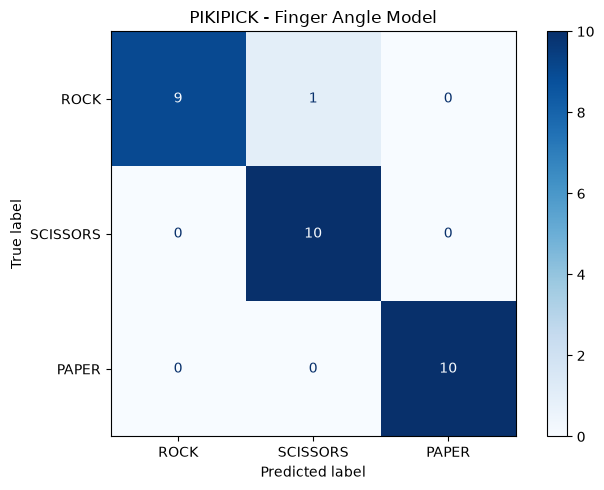


[모델 저장 완료]
c:\Users\mbc\rock\mediapipe_training\pikipick_angle_randomforest.joblib


In [13]:

# ============================================================
# 13. PIKIPICK 관절 각도 기반 모델 학습
# 목적: 기존 3D 좌표 모델과 성능 비교
# 모델: RandomForestClassifier
# 입력: 검지 / 중지 / 약지 / 새끼 관절 각도
# ============================================================

# 0. 필요한 라이브러리
import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# 1. 앞에서 계산한 angle_df 사용
# NONE은 이번 모델에서 제외
LABELS = ["ROCK", "SCISSORS", "PAPER"]

angle_data = angle_df[
    angle_df["label"].isin(LABELS)
].copy()

# 2. 학습에 사용할 관절 각도
ANGLE_COLUMNS = [
    "INDEX",
    "MIDDLE",
    "RING",
    "PINKY"
]

# 3. 입력과 정답 준비
X_angle = angle_data[ANGLE_COLUMNS].to_numpy()
y_angle = angle_data["label"].to_numpy()

# 4. 촬영 세션을 기준으로 분리
train_mask = (
    angle_data["session_id"].astype(str)
    == "20261106_183039"
).to_numpy()

test_mask = (
    angle_data["session_id"].astype(str)
    == "20261106_185536"
).to_numpy()

X_train_angle = X_angle[train_mask]
X_test_angle = X_angle[test_mask]

y_train_angle = y_angle[train_mask]
y_test_angle = y_angle[test_mask]

# 5. 모델 생성
angle_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# 6. 모델 학습
angle_model.fit(X_train_angle, y_train_angle)

# 7. 평가 데이터 예측
y_pred_angle = angle_model.predict(X_test_angle)

# 8. 정확도 출력
angle_accuracy = accuracy_score(
    y_test_angle,
    y_pred_angle
)

print("========== 관절 각도 모델 평가 ==========")
print(f"Accuracy: {angle_accuracy:.2%}")

print("\n[클래스별 평가]")
print(
    classification_report(
        y_test_angle,
        y_pred_angle,
        labels=LABELS,
        zero_division=0,
        digits=4
    )
)

# 9. 혼동행렬 시각화
cm_angle = confusion_matrix(
    y_test_angle,
    y_pred_angle,
    labels=LABELS
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_angle,
    display_labels=LABELS
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("PIKIPICK - Finger Angle Model")
plt.tight_layout()
plt.show()

# 10. 관절 각도 모델 저장
MODEL_PATH = Path.cwd() / "pikipick_angle_randomforest.joblib"

joblib.dump({
    "model": angle_model,
    "labels": LABELS,
    "features": ANGLE_COLUMNS,
    "finger_joints": FINGER_JOINTS,
    "feature_type": "pip_joint_angle_v1"
}, MODEL_PATH)

print("\n[모델 저장 완료]")
print(MODEL_PATH)
